In [2]:
import pandas as pd
import numpy as np
import prince
import matplotlib.pyplot as plt

dados = pd.DataFrame(
    [
        [68, 20, 15, 5],
        [119, 84, 54, 29],
        [26, 17, 14, 14],
        [7, 94, 10, 16],
    ],
    index=["Preto", "Castanho", "Ruivo", "Loiro"],
    columns=["Castanho", "Azul", "Avelã", "Verde"],
)
dados

,Castanho,Azul,Avelã,Verde
Preto,68,20,15,5
Castanho,119,84,54,29
Ruivo,26,17,14,14
Loiro,7,94,10,16


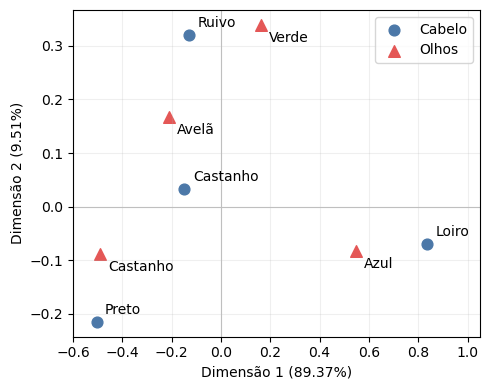

cos²  Ctr 1 (%)  Ctr 2 (%)
Variável Nível                                
Cabelo   Preto     0.990       22.2       37.9
         Castanho  0.906        5.1        2.3
         Ruivo     0.945        1.0       55.1
         Loiro     1.000       71.7        4.7
Olhos    Castanho  0.998       43.1       13.0
         Azul      1.000       52.1       11.2
         Avelã     0.879        3.4       19.8
         Verde     0.948        1.4       55.9

In [11]:
SEED = 42

ca = prince.CA(n_components=3, random_state=SEED).fit(dados)

row_coords = ca.row_coordinates(dados)
col_coords = ca.column_coordinates(dados)
prop = np.array(ca.percentage_of_variance_)
acum = np.cumsum(prop)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(row_coords[0], row_coords[1], color="#4C78A8", marker="o", s=60, label="Cabelo")
ax.scatter(col_coords[0], col_coords[1], color="#E45756", marker="^", s=70, label="Olhos")

for rotulo, linha in row_coords.iterrows():
    ax.annotate(rotulo, (linha[0], linha[1]), xytext=(6, 6), textcoords="offset points")

for rotulo, col in col_coords.iterrows():
    ax.annotate(rotulo, (col[0], col[1]), xytext=(6, -12), textcoords="offset points")

ax.axhline(0, color="0.75", linewidth=0.8)
ax.axvline(0, color="0.75", linewidth=0.8)
ax.set_xlabel(f"Dimensão 1 ({prop[0]:.2f}%)")
ax.set_ylabel(f"Dimensão 2 ({prop[1]:.2f}%)")
ax.set_xlim(-0.6, 1.05)
ax.grid(alpha=0.2)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
cos2_r = ca.row_cosine_similarities(dados)
cos2_c = ca.column_cosine_similarities(dados)
ctr_r = ca.row_contributions_
ctr_c = ca.column_contributions_

cos2_total_r = (cos2_r[0] + cos2_r[1]).round(3)
cos2_total_c = (cos2_c[0] + cos2_c[1]).round(3)

pd.DataFrame({
    "Variável": ["Cabelo"] * 4 + ["Olhos"] * 4,
    "Nível": list(dados.index) + list(dados.columns),
    "cos²": list(cos2_total_r) + list(cos2_total_c),
    "Ctr 1 (%)": list((ctr_r[0] * 100).round(1)) + list((ctr_c[0] * 100).round(1)),
    "Ctr 2 (%)": list((ctr_r[1] * 100).round(1)) + list((ctr_c[1] * 100).round(1)),
}).set_index(["Variável", "Nível"])

In [13]:
prop

array([89.37273217,  9.51491134,  1.11235648])